# 01 · Bias, variance, overfitting and regularisation

**Goal:** see underfitting and overfitting with your own eyes, measure them, and fix them.
**Time:** ~2 hours. **Sources:** see this module's [README](README.md).

| Term | Plain meaning | How you spot it |
|---|---|---|
| **Bias** | The model is too simple to capture the pattern | Train error **high**, validation error high |
| **Variance** | The model memorises noise in the training set | Train error **low**, validation error much higher |
| **Underfitting** | High bias | Both curves high and close together |
| **Overfitting** | High variance | Big gap between train and validation |

Expected test error ≈ bias² + variance + irreducible noise. You trade bias against variance by changing
model complexity, the amount of data, or regularisation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, validation_curve, learning_curve
from sklearn.metrics import mean_squared_error
from sklearn.datasets import load_breast_cancer

rng = np.random.default_rng(42)

## 1. A toy problem: noisy sine wave
The true function is `sin(2πx)`. We only see 30 noisy samples. Let's fit polynomials of degree 1, 4 and 15.

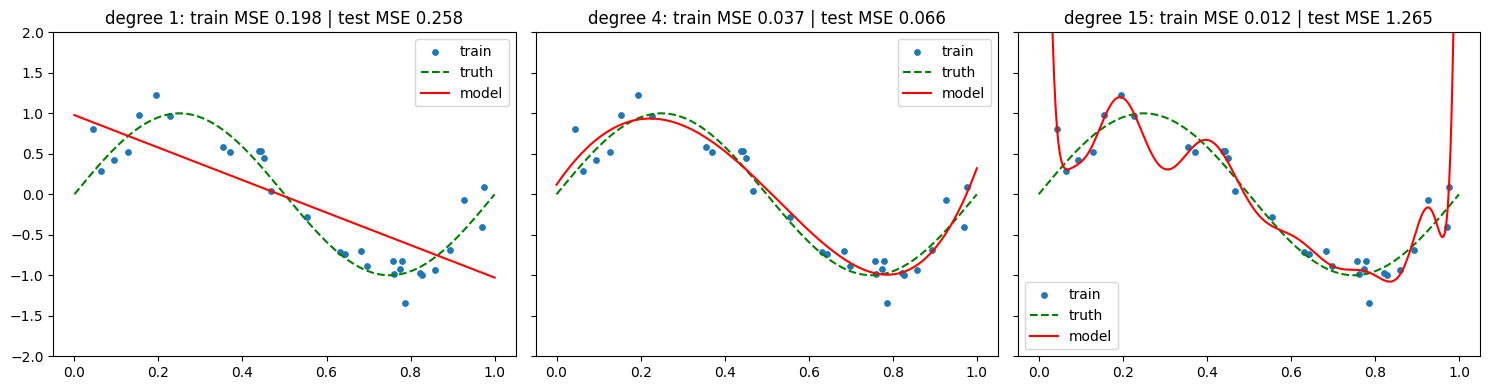

In [2]:
def make_data(n, noise=0.25):
    x = np.sort(rng.uniform(0, 1, n))
    y = np.sin(2 * np.pi * x) + rng.normal(0, noise, n)
    return x.reshape(-1, 1), y

X_train, y_train = make_data(30)
X_test, y_test = make_data(200)
grid = np.linspace(0, 1, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, degree in zip(axes, [1, 4, 15]):
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)
    tr = mean_squared_error(y_train, model.predict(X_train))
    te = mean_squared_error(y_test, model.predict(X_test))
    ax.scatter(X_train, y_train, s=15, label="train")
    ax.plot(grid, np.sin(2 * np.pi * grid), "g--", label="truth")
    ax.plot(grid, model.predict(grid), "r", label="model")
    ax.set_ylim(-2, 2)
    ax.set_title(f"degree {degree}: train MSE {tr:.3f} | test MSE {te:.3f}")
    ax.legend()
plt.tight_layout(); plt.show()

**Read the titles.** Degree 1 is bad on both sets (bias). Degree 15 is great on train and bad on test
(variance). Degree 4 is the sweet spot.

## 2. Validation curve: error vs model complexity
`validation_curve` runs cross-validation for each value of one hyperparameter.

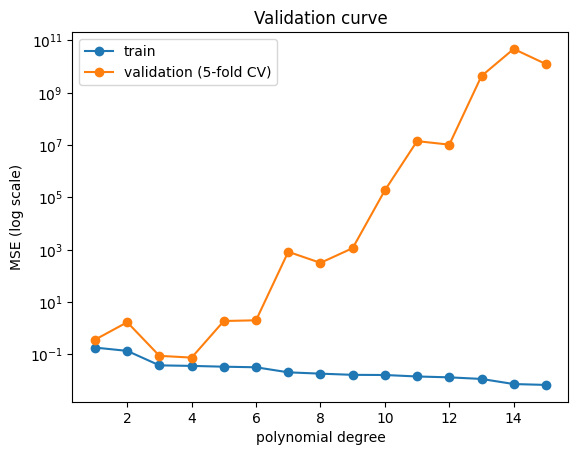

best degree by CV: 4


In [3]:
degrees = np.arange(1, 16)
model = make_pipeline(PolynomialFeatures(), LinearRegression())
train_scores, val_scores = validation_curve(
    model, X_train, y_train, param_name="polynomialfeatures__degree", param_range=degrees,
    cv=5, scoring="neg_mean_squared_error")

plt.plot(degrees, -train_scores.mean(axis=1), "o-", label="train")
plt.plot(degrees, -val_scores.mean(axis=1), "o-", label="validation (5-fold CV)")
plt.yscale("log"); plt.xlabel("polynomial degree"); plt.ylabel("MSE (log scale)")
plt.legend(); plt.title("Validation curve"); plt.show()
print("best degree by CV:", degrees[np.argmax(val_scores.mean(axis=1))])

## 3. Learning curve: does more data help?
- If train and validation scores **converge at a low score** → high bias → more data won't help; use a richer model.
- If there is a **gap that shrinks** as data grows → high variance → more data (or regularisation) helps.

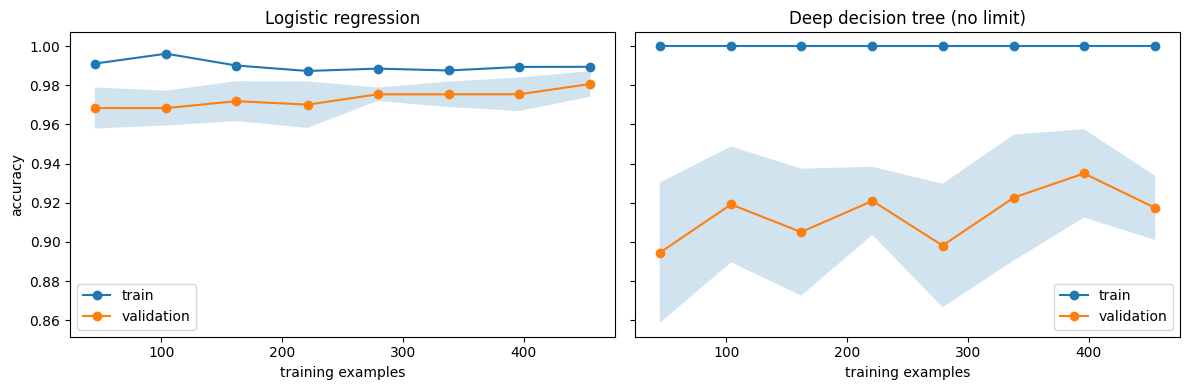

In [4]:
X, y = load_breast_cancer(return_X_y=True)
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Deep decision tree (no limit)": DecisionTreeClassifier(random_state=0),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    sizes, tr, va = learning_curve(m, X, y, cv=5, train_sizes=np.linspace(0.1, 1.0, 8),
                                   scoring="accuracy", random_state=0, shuffle=True)
    ax.plot(sizes, tr.mean(1), "o-", label="train")
    ax.plot(sizes, va.mean(1), "o-", label="validation")
    ax.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
    ax.set_title(name); ax.set_xlabel("training examples"); ax.legend()
axes[0].set_ylabel("accuracy"); plt.tight_layout(); plt.show()

The unrestricted tree has **train accuracy = 1.0** at every size: it memorises. That gap is variance.

## 4. Regularisation: keep the complex model, shrink its weights
Ridge (L2) adds `alpha * Σ w²` to the loss. Bigger `alpha` → smaller weights → smoother curve.
Lasso (L1) adds `alpha * Σ |w|` and pushes some weights to exactly zero (feature selection).

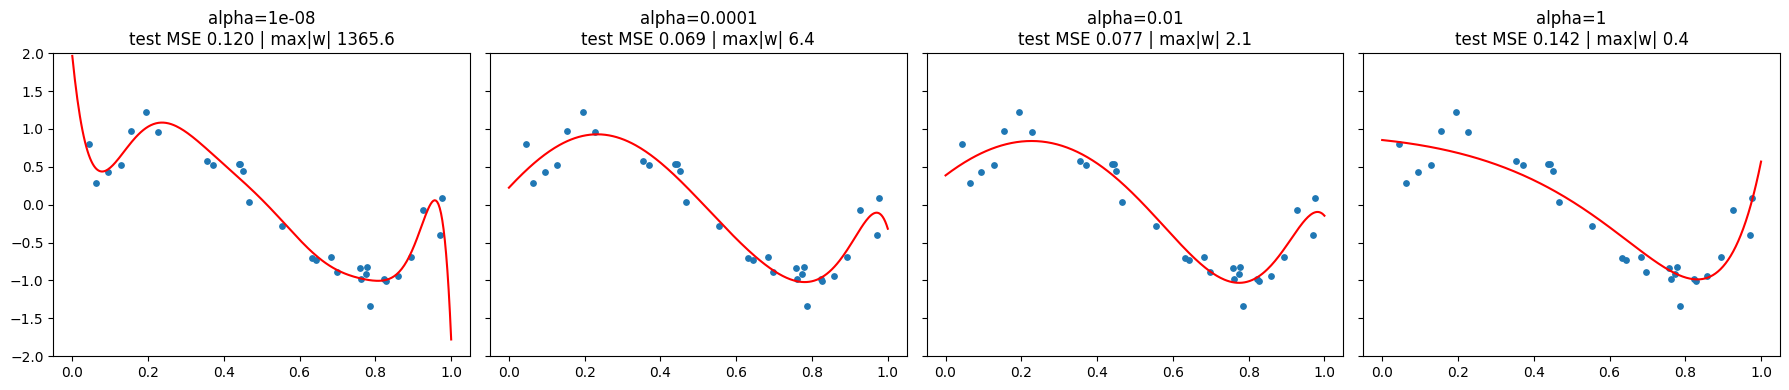

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, alpha in zip(axes, [1e-8, 1e-4, 1e-2, 1]):
    m = make_pipeline(PolynomialFeatures(15), StandardScaler(), Ridge(alpha=alpha))
    m.fit(X_train, y_train)
    te = mean_squared_error(y_test, m.predict(X_test))
    w = np.abs(m[-1].coef_).max()
    ax.scatter(X_train, y_train, s=15); ax.plot(grid, m.predict(grid), "r")
    ax.set_ylim(-2, 2); ax.set_title(f"alpha={alpha:g}\ntest MSE {te:.3f} | max|w| {w:.1f}")
plt.tight_layout(); plt.show()

## Other ways to fight overfitting
| Tool | Where it applies |
|---|---|
| More / cleaner data, data augmentation | Everything, especially vision |
| L1 / L2 penalty (`C` in sklearn = 1/alpha) | Linear models, neural nets (weight decay) |
| Limit depth, min samples per leaf | Trees |
| Bagging (random forest), early stopping in boosting | Ensembles |
| Dropout, early stopping, batch norm | Neural networks |
| Feature selection, simpler model | Everywhere |

## ✍️ Your turn
1. Change `noise` in `make_data` to 0.05 and 0.6. How does the best degree change? Why?
2. Draw a validation curve for `DecisionTreeClassifier(max_depth=d)` on breast cancer for d = 1..15.
3. In your own words (3 sentences, in `notes.md`): what is the bias–variance trade-off?

In [6]:
# 2. Your code here: validation curve for max_depth

## 🎯 Interview check (answer aloud, < 1 minute each)
- Your model has 99% train accuracy and 75% validation accuracy. What is happening and what do you try first?
- Both train and validation accuracy are 70%. What now?
- L1 vs L2: what does each do to the weights?
- Why does more data reduce variance but not bias?